Running simulations...
Tick 0/200 completed
Tick 20/200 completed
Tick 40/200 completed
Tick 60/200 completed
Tick 80/200 completed
Tick 100/200 completed
Tick 120/200 completed
Tick 140/200 completed
Tick 160/200 completed
Tick 180/200 completed
Creating separate animations...
Standard SOM animation saved
RKDO SOM animation saved
Creating combined animation...
Combined animation saved
Creating KL divergence comparison plot...
KL divergence comparison plot saved

All outputs saved to:
- ./output/standard_som_mosaic.gif
- ./output/rkdo_som_mosaic.gif
- ./output/combined_som_comparison.gif
- ./output/kl_comparison.png


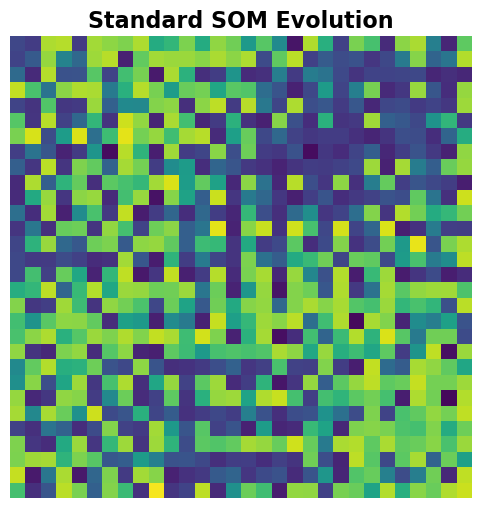

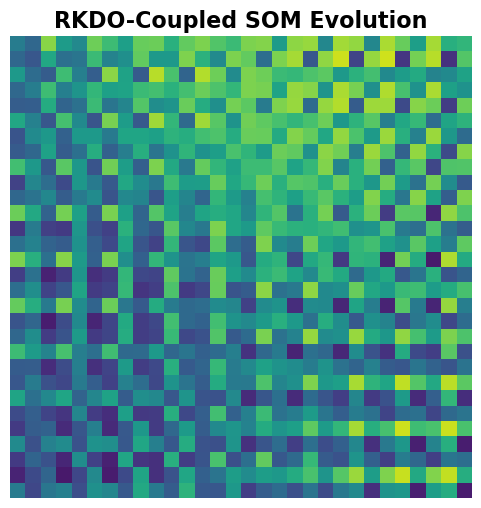

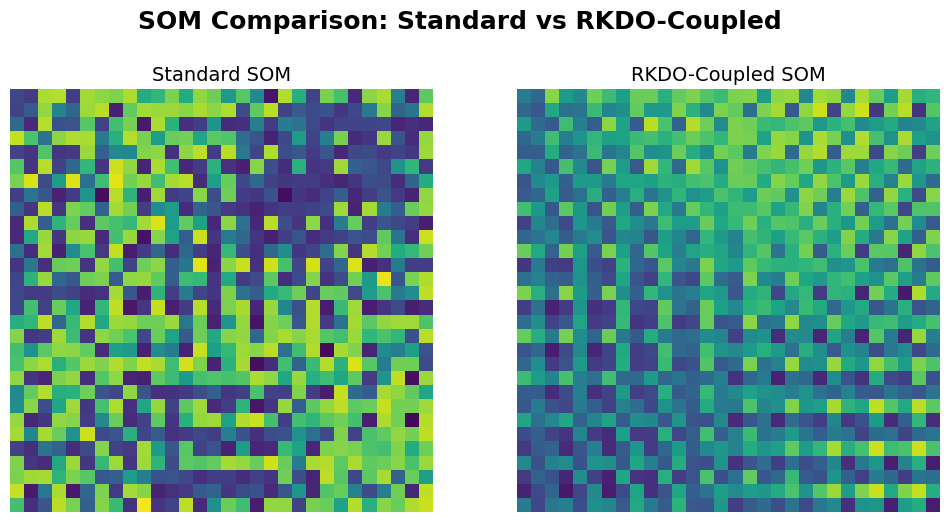

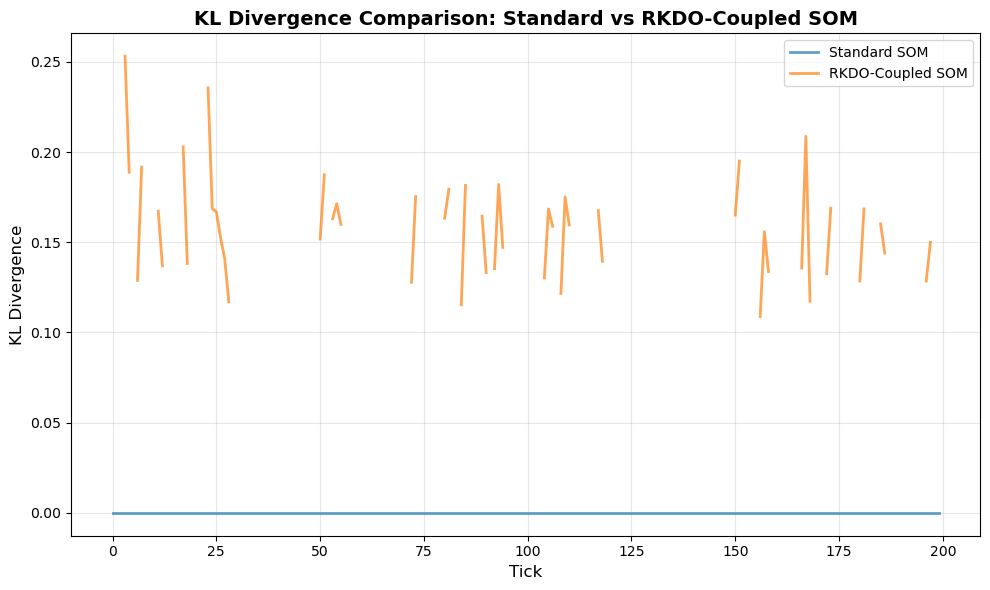

In [4]:
# RKDO-coupled vs Standard Online SOM animation over CCA patches
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.animation import PillowWriter
from scipy.stats import entropy

# ---- CCA Sensor (same) ----
class CCASensor:
    def __init__(self, size=100, k=4, m=2, seed=123):
        self.n, self.k = size, k
        self.rng = np.random.default_rng(seed)
        self.grid = self.rng.integers(0, k, size=(size, size))
        self.neigh = [(dx,dy) for dx in (-1,0,1) for dy in (-1,0,1) if dx or dy]

    def step(self):
        g = self.grid; k=self.k
        newg = g.copy()
        for dx,dy in self.neigh:
            neigh = np.roll(np.roll(g,dx,0),dy,1)
            mask = neigh == ((g+1)%k)
            newg[mask] = (g[mask]+1)%k
        self.grid = newg

    def patches(self, sz=3):
        out=[]
        for i in range(0,self.n-sz+1,sz):
            for j in range(0,self.n-sz+1,sz):
                out.append(self.grid[i:i+sz,j:j+sz].flatten())
        return out

# ---- Standard Online SOM (your original implementation) ----
class OnlineSOM:
    def __init__(self, x, y, input_len, sigma=1.5, lr=0.4, seed=42):
        self.x, self.y, self.input_len = x, y, input_len
        self.sigma0, self.lr0 = sigma, lr
        self.rng = np.random.default_rng(seed)
        self.weights = self.rng.random((x, y, input_len))
        self.locations = np.array([[i, j] for i in range(x) for j in range(y)])
        self.iteration = 0

    def _decay_sigma(self, t, max_t=10000):
        return self.sigma0 * np.exp(-t / (max_t / np.log(self.sigma0 + 1e-8)))

    def _decay_lr(self, t, max_t=10000):
        return self.lr0 * np.exp(-t / max_t)

    def update(self, v, max_t=10000):
        # Best Matching Unit
        dists = np.linalg.norm(self.weights - v.reshape(1, 1, -1), axis=2)
        bmu = np.unravel_index(np.argmin(dists), (self.x, self.y))
        bmu_idx = bmu[0] * self.y + bmu[1]

        # Neighborhood function
        sigma = self._decay_sigma(self.iteration, max_t)
        lr = self._decay_lr(self.iteration, max_t)
        d = np.linalg.norm(self.locations - self.locations[bmu_idx], axis=1)
        h = np.exp(-(d ** 2) / (2 * sigma ** 2)).reshape(self.x, self.y)

        # Weight update
        self.weights += lr * h[:, :, np.newaxis] * (v - self.weights)
        self.iteration += 1

    def update_batch(self, data, max_t=20000):
        for vec in data:
            self.update(vec, max_t)
        return 0  # No KL divergence for standard SOM

    def snapshot_prototypes(self):
        prototypes = np.zeros((self.x * self.y, self.input_len))
        counts = np.zeros(self.x * self.y, dtype=int)
        # We'll approximate prototypes using current weights (already averages)
        for i in range(self.x):
            for j in range(self.y):
                idx = i * self.y + j
                prototypes[idx] = self.weights[i, j]
                counts[idx] = 1
        return prototypes.reshape(self.x, self.y, 3, 3) * 3  # scale back to cell states 0-3

    def snapshot(self):
        return self.snapshot_prototypes()

# ---- RKDO-coupled Online SOM ----
class RKDOSOM:
    def __init__(self, x, y, dim, lr0=0.3, sigma0=1.5, alpha=0.2, seed=0):
        self.x, self.y, self.dim = x, y, dim
        self.lr0, self.sigma0, self.alpha = lr0, sigma0, alpha
        self.rng = np.random.default_rng(seed)
        self.weights = self.rng.random((x,y,dim))
        self.locations = np.array([[i,j] for i in range(x) for j in range(y)])
        self.t = 0
        self.p_prior = np.ones(x*y)/ (x*y)  # uniform prior
        self.kl0 = None

    def _lr(self, kl):
        if self.kl0 is None:
            self.kl0 = kl if kl>0 else 1e-6
        scale = min(1.0, kl / self.kl0)
        return self.lr0 * scale

    def _sigma(self, iter, max_iter=10000):
        return self.sigma0 * np.exp(-iter / max_iter)

    def bmu(self, v):
        dists = np.linalg.norm(self.weights - v.reshape(1,1,-1), axis=2)
        return np.unravel_index(np.argmin(dists),(self.x,self.y))

    def update_batch(self, data):
        # Build q distribution counts
        counts = np.zeros(self.x*self.y)
        bmus=[]
        for v in data:
            b = self.bmu(v)
            bmus.append(b)
            idx = b[0]*self.y + b[1]
            counts[idx]+=1
        if counts.sum()==0:
            return
        q = counts / counts.sum()
        kl = entropy(self.p_prior, q)
        # adaptive lr and sigma
        lr = self._lr(kl)
        sigma = self._sigma(self.t)
        # neighborhood weights update
        for v, b in zip(data, bmus):
            b_idx = b[0]*self.y + b[1]
            d = np.linalg.norm(self.locations - self.locations[b_idx], axis=1)
            h = np.exp(-(d**2)/(2*sigma**2)).reshape(self.x,self.y)
            self.weights += lr * h[:,:,None] * (v - self.weights)
        # RKDO prior update
        self.p_prior = (1-self.alpha)*self.p_prior + self.alpha*q
        self.t += 1
        return kl

    def snapshot(self):
        # return 3x3 prototypes scaled back
        return self.weights.reshape(self.x,self.y,3,3)*3

# ---- Simulation ----
# Create two sensors with same seed for fair comparison
sensor1 = CCASensor(seed=123)
sensor2 = CCASensor(seed=123)

# Create both SOM types
som_standard = OnlineSOM(10, 10, 9, sigma=1.5, lr=0.4, seed=42)
som_rkdo = RKDOSOM(10, 10, 9, lr0=0.4, sigma0=1.5, alpha=0.2, seed=0)

frames_standard = []
frames_rkdo = []
kl_series_standard = []
kl_series_rkdo = []

ticks = 200
print("Running simulations...")
for t in range(ticks):
    # Step both sensors
    sensor1.step()
    sensor2.step()
    
    # Get patches from both sensors
    vecs1 = np.array(sensor1.patches()) / 3.0
    vecs2 = np.array(sensor2.patches()) / 3.0
    
    # Update both SOMs
    kl_std = som_standard.update_batch(vecs1, max_t=20000)
    kl_rkdo = som_rkdo.update_batch(vecs2)
    
    kl_series_standard.append(kl_std)
    kl_series_rkdo.append(kl_rkdo)
    
    # Collect frames every 20 ticks
    if t % 20 == 0:
        frames_standard.append(som_standard.snapshot())
        frames_rkdo.append(som_rkdo.snapshot())
        print(f"Tick {t}/200 completed")

# ---- Animation functions ----
def mosaic(proto):
    return np.block([[proto[i,j] for j in range(10)] for i in range(10)])

# ---- Separate Animations ----
print("Creating separate animations...")

# Standard SOM animation
fig1, ax1 = plt.subplots(figsize=(6,6))
img1 = ax1.imshow(mosaic(frames_standard[0]), cmap='viridis', vmin=0, vmax=3)
ax1.set_title('Standard SOM Evolution', fontsize=16, fontweight='bold')
ax1.axis('off')

def update_standard(frame):
    img1.set_data(mosaic(frame))
    return [img1]

ani_standard = animation.FuncAnimation(fig1, update_standard, frames=frames_standard, interval=600, blit=True)
ani_standard.save("./output/standard_som_mosaic.gif", writer=PillowWriter(fps=2))
print("Standard SOM animation saved")

# RKDO SOM animation
fig2, ax2 = plt.subplots(figsize=(6,6))
img2 = ax2.imshow(mosaic(frames_rkdo[0]), cmap='viridis', vmin=0, vmax=3)
ax2.set_title('RKDO-Coupled SOM Evolution', fontsize=16, fontweight='bold')
ax2.axis('off')

def update_rkdo(frame):
    img2.set_data(mosaic(frame))
    return [img2]

ani_rkdo = animation.FuncAnimation(fig2, update_rkdo, frames=frames_rkdo, interval=600, blit=True)
ani_rkdo.save("./output/rkdo_som_mosaic.gif", writer=PillowWriter(fps=2))
print("RKDO SOM animation saved")

# ---- Combined Animation ----
print("Creating combined animation...")

fig3, (ax3_left, ax3_right) = plt.subplots(1, 2, figsize=(12, 6))
fig3.suptitle('SOM Comparison: Standard vs RKDO-Coupled', fontsize=18, fontweight='bold')

img3_left = ax3_left.imshow(mosaic(frames_standard[0]), cmap='viridis', vmin=0, vmax=3)
ax3_left.set_title('Standard SOM', fontsize=14)
ax3_left.axis('off')

img3_right = ax3_right.imshow(mosaic(frames_rkdo[0]), cmap='viridis', vmin=0, vmax=3)
ax3_right.set_title('RKDO-Coupled SOM', fontsize=14)
ax3_right.axis('off')

def update_combined(frame_idx):
    img3_left.set_data(mosaic(frames_standard[frame_idx]))
    img3_right.set_data(mosaic(frames_rkdo[frame_idx]))
    return [img3_left, img3_right]

ani_combined = animation.FuncAnimation(fig3, update_combined, frames=len(frames_standard), interval=600, blit=True)
ani_combined.save("./output/combined_som_comparison.gif", writer=PillowWriter(fps=2))
print("Combined animation saved")

# ---- KL Divergence Comparison Plot ----
print("Creating KL divergence comparison plot...")

plt.figure(figsize=(10, 6))
plt.plot(kl_series_standard, label='Standard SOM', linewidth=2, alpha=0.7)
plt.plot(kl_series_rkdo, label='RKDO-Coupled SOM', linewidth=2, alpha=0.7)
plt.xlabel("Tick", fontsize=12)
plt.ylabel("KL Divergence", fontsize=12)
plt.title("KL Divergence Comparison: Standard vs RKDO-Coupled SOM", fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("./output/kl_comparison.png", dpi=300, bbox_inches='tight')
print("KL divergence comparison plot saved")

# Print final paths
print("\nAll outputs saved to:")
print("- ./output/standard_som_mosaic.gif")
print("- ./output/rkdo_som_mosaic.gif") 
print("- ./output/combined_som_comparison.gif")
print("- ./output/kl_comparison.png")